<a href="https://colab.research.google.com/github/ezreals-ares/PBL_Meat_Freshness/blob/fs3/TrainModel/SVM_experimental.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Meat Freshness Classification
## Support Vector Machine (SVM) + Color Histogram + LBP

Notebook ini mengimplementasikan klasifikasi kesegaran daging menggunakan pendekatan **Traditional Machine Learning**:

- **Feature Extraction**: Color Histogram (RGB + HSV) & Local Binary Pattern (LBP)
- **Classifier**: Support Vector Machine (SVM) dengan kernel RBF
- **Dataset**: 3 kelas — Fresh Meat (0), Half-Fresh Meat (1), Spoiled Meat (2)

# 2. Import Libraries

Library yang digunakan dalam proyek ini:

- **NumPy** — komputasi numerik
- **Pandas** — manipulasi data
- **OpenCV** — pemrosesan gambar (Color Histogram)
- **scikit-image** — ekstraksi fitur LBP
- **scikit-learn** — SVM, normalisasi, dan evaluasi model
- **Matplotlib** — visualisasi
- **tqdm** — progress bar saat loading dataset
- **joblib** — menyimpan model

In [ ]:
# =====================================================
# Import Libraries
# =====================================================

import os
import glob
import random
import warnings
import joblib

warnings.filterwarnings("ignore")

# Data Manipulation
import numpy as np
import pandas as pd

# Image Processing
import cv2
from skimage.feature import local_binary_pattern

# Machine Learning
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import label_binarize

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc
)

# Visualization
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 120

# Progress Bar
from tqdm import tqdm

# Random Seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("=" * 50)
print("Libraries Successfully Imported")
print("=" * 50)
print(f"OpenCV Version     : {cv2.__version__}")
print(f"NumPy Version      : {np.__version__}")
print(f"Pandas Version     : {pd.__version__}")

Libraries Successfully Imported
OpenCV Version     : 4.14.0
NumPy Version      : 2.1.3
Pandas Version     : 2.2.3


# 3. Dataset Loading

Dataset dimuat dari Google Drive. Label di-generate otomatis berdasarkan nama file:

| Prefix Nama File | Label | Kelas |
|---|---|---|
| `FRESH-` | 0 | Fresh Meat |
| `HALF-FRESH-` | 1 | Half-Fresh Meat |
| `SPOILED-` | 2 | Spoiled Meat |

In [ ]:
# ============================================================
# Mount Google Drive
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

print("Google Drive berhasil di-mount!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive berhasil di-mount!


In [ ]:
import os
import glob
import pandas as pd

# ============================================================
# Konfigurasi Path Dataset
# ============================================================

GDRIVE_DATASET_PATH = "/content/drive/MyDrive/dataset/Meat Freshness.v1-new-dataset.multiclass"

if not os.path.exists(GDRIVE_DATASET_PATH):
    raise Exception(
        f"Dataset tidak ditemukan di: {GDRIVE_DATASET_PATH}\n"
        "Pastikan:\n"
        "  1. Google Drive sudah di-mount\n"
        "  2. Folder dataset sudah diupload ke Google Drive\n"
        "  3. Path GDRIVE_DATASET_PATH sudah benar"
    )

DATASET_ROOT = GDRIVE_DATASET_PATH
print("Dataset root      :", DATASET_ROOT)

# Cari folder train dan valid
train_path = None
valid_path = None

for root, dirs, files in os.walk(DATASET_ROOT):
    basename = os.path.basename(root)
    if basename == "train":
        train_path = root
    elif basename == "valid":
        valid_path = root

if train_path is None or valid_path is None:
    raise Exception(
        f"Folder train/valid tidak ditemukan di: {DATASET_ROOT}\n"
        f"Isi folder: {os.listdir(DATASET_ROOT)}"
    )

print("Train :", train_path)
print("Valid :", valid_path)

# Load daftar gambar
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tiff", ".webp")
train_images = [p for p in glob.glob(os.path.join(train_path, "*"))
                if p.lower().endswith(image_extensions)]
valid_images = [p for p in glob.glob(os.path.join(valid_path, "*"))
                if p.lower().endswith(image_extensions)]

train_df = pd.DataFrame({"image_path": train_images})
valid_df  = pd.DataFrame({"image_path": valid_images})

# ============================================================
# Generate Labels
# ============================================================

def get_label(filepath):
    """FRESH=0, HALF-FRESH=1, SPOILED=2"""
    name = os.path.basename(filepath).upper()
    if name.startswith("HALF"):
        return 1
    elif name.startswith("FRESH"):
        return 0
    else:
        return 2

train_df["label"] = train_df["image_path"].apply(get_label)
valid_df["label"]  = valid_df["image_path"].apply(get_label)

print(f"Training Images   : {len(train_df)}")
print(f"Validation Images : {len(valid_df)}")

display(train_df.head())

Dataset root      : /content/drive/MyDrive/dataset/Meat Freshness.v1-new-dataset.multiclass
Train : /content/drive/MyDrive/dataset/Meat Freshness.v1-new-dataset.multiclass/train
Valid : /content/drive/MyDrive/dataset/Meat Freshness.v1-new-dataset.multiclass/valid
Training Images   : 1815
Validation Images : 451


,image_path,label
0,/content/drive/MyDrive/dataset/Meat Freshness....,2
1,/content/drive/MyDrive/dataset/Meat Freshness....,2
2,/content/drive/MyDrive/dataset/Meat Freshness....,1
3,/content/drive/MyDrive/dataset/Meat Freshness....,1
4,/content/drive/MyDrive/dataset/Meat Freshness....,1


# 4. Exploratory Data Analysis (EDA)

Sebelum membangun model, kita analisis distribusi kelas dan contoh gambar dari dataset untuk memastikan data sudah termuat dengan benar.

TRAINING DATASET


,image_path,label,class
0,/content/drive/MyDrive/dataset/Meat Freshness....,2,Spoiled Meat
1,/content/drive/MyDrive/dataset/Meat Freshness....,2,Spoiled Meat
2,/content/drive/MyDrive/dataset/Meat Freshness....,1,Half-Fresh Meat
3,/content/drive/MyDrive/dataset/Meat Freshness....,1,Half-Fresh Meat
4,/content/drive/MyDrive/dataset/Meat Freshness....,1,Half-Fresh Meat



Training Class Distribution


,count
class,
Fresh Meat,675
Half-Fresh Meat,630
Spoiled Meat,510



Validation Class Distribution


,count
class,
Fresh Meat,178
Half-Fresh Meat,159
Spoiled Meat,114


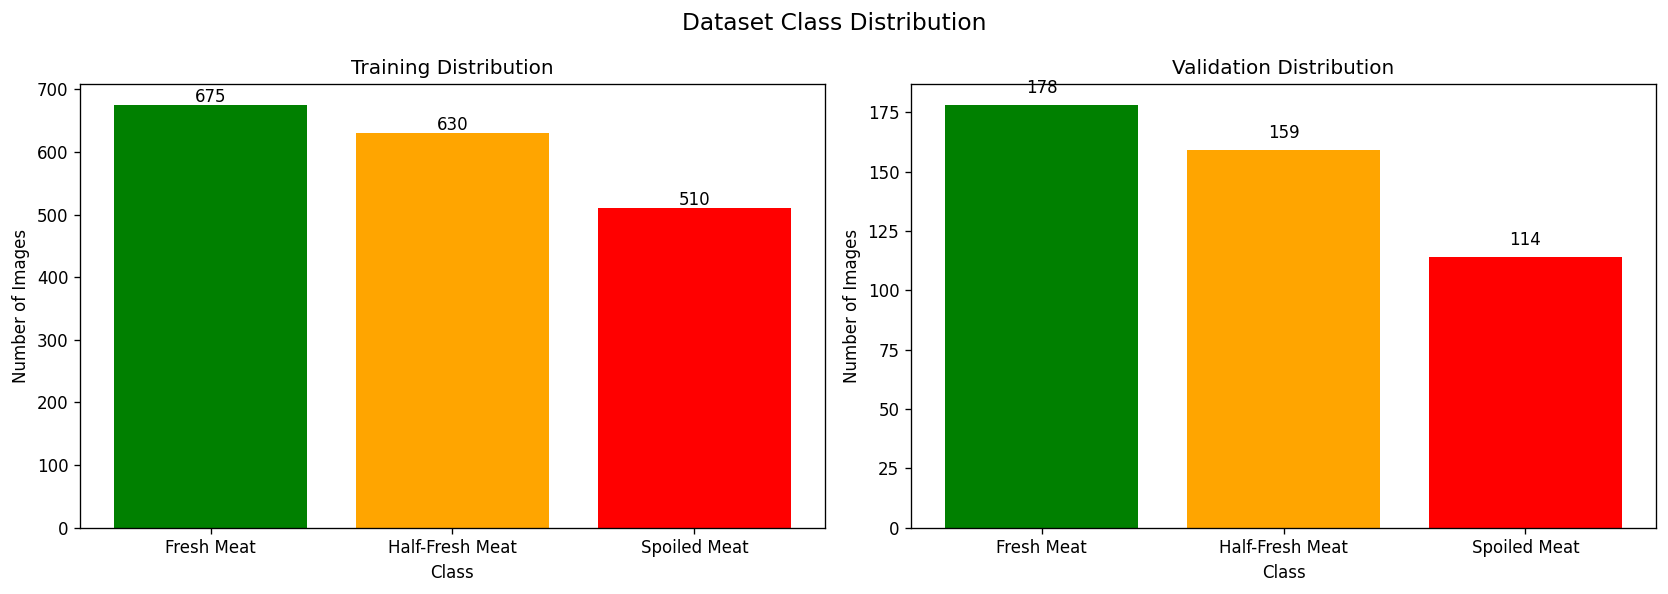

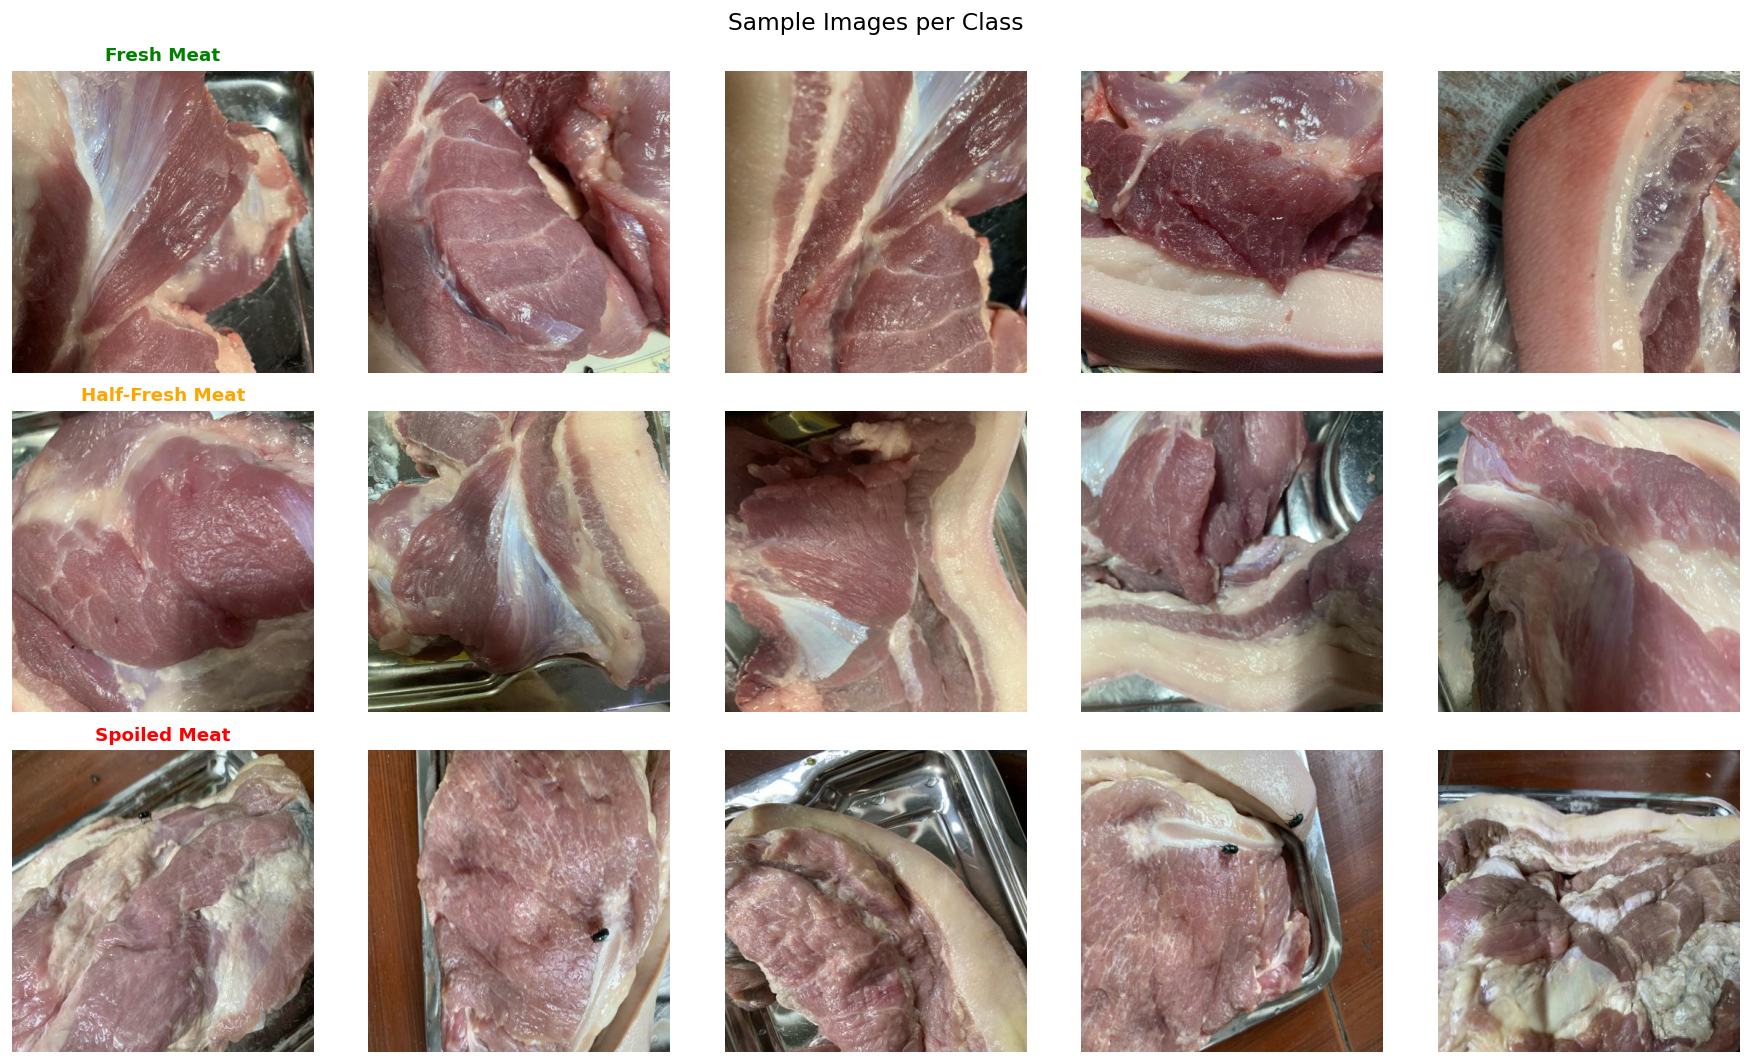

In [ ]:
CLASS_NAMES = {0: "Fresh Meat", 1: "Half-Fresh Meat", 2: "Spoiled Meat"}
CLASS_COLORS = {0: "green", 1: "orange", 2: "red"}

# ============================================================
# Training Dataset Overview
# ============================================================

train_df["class"] = train_df["label"].map(CLASS_NAMES)
valid_df["class"] = valid_df["label"].map(CLASS_NAMES)

print("=" * 50)
print("TRAINING DATASET")
print("=" * 50)
display(train_df.head())

print("\nTraining Class Distribution")
display(train_df["class"].value_counts())

print("\nValidation Class Distribution")
display(valid_df["class"].value_counts())

# ============================================================
# Class Distribution Bar Chart
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, df, title in zip(
    axes,
    [train_df, valid_df],
    ["Training Distribution", "Validation Distribution"]
):
    counts = df["class"].value_counts()
    colors = ["green", "orange", "red"]
    ax.bar(counts.index, counts.values, color=colors[:len(counts)])
    ax.set_title(title)
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of Images")
    for i, (idx, val) in enumerate(counts.items()):
        ax.text(i, val + 5, str(val), ha="center", fontsize=10)

plt.suptitle("Dataset Class Distribution", fontsize=14)
plt.tight_layout()
plt.show()

# ============================================================
# Sample Images
# ============================================================

fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for class_label in [0, 1, 2]:
    samples = train_df[train_df["label"] == class_label].sample(5, random_state=SEED)
    for col, (_, row) in enumerate(samples.iterrows()):
        img = cv2.imread(row["image_path"])
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[class_label][col].imshow(img_rgb)
        axes[class_label][col].axis("off")
        if col == 0:
            axes[class_label][col].set_title(
                CLASS_NAMES[class_label],
                color=CLASS_COLORS[class_label],
                fontsize=11,
                fontweight="bold"
            )

plt.suptitle("Sample Images per Class", fontsize=14)
plt.tight_layout()
plt.show()

# 5. Feature Extraction

Karena SVM adalah model **Traditional ML** yang tidak dapat memproses piksel gambar secara langsung, kita perlu mengekstrak fitur yang merepresentasikan karakteristik visual gambar.

Dua jenis fitur yang digunakan:

### 🎨 Color Histogram (RGB + HSV)
Menghitung distribusi intensitas warna pada tiap channel. Daging segar memiliki warna merah cerah, sedangkan daging busuk cenderung coklat/abu-abu.

- **RGB**: 3 channel × 32 bins = **96 fitur**
- **HSV**: 3 channel × 32 bins = **96 fitur**

### 🔲 Local Binary Pattern (LBP)
Mendeskripsikan **tekstur lokal** di sekitar tiap piksel dengan membandingkan nilai piksel pusat dengan tetangganya. Tekstur permukaan daging berubah seiring kesegaran.

- Radius: 1, Points: 8 → histogram dari pola LBP = **10 fitur**

### Total Fitur per Gambar: **202 fitur**

In [ ]:
# ============================================================
# Feature Extraction Functions
# ============================================================

IMG_SIZE    = (128, 128)   # Ukuran resize sebelum ekstraksi fitur
HIST_BINS   = 32           # Bins untuk histogram warna
LBP_RADIUS  = 1            # Radius LBP
LBP_POINTS  = 8            # Jumlah titik sampling LBP

def extract_color_histogram(image_bgr, bins=HIST_BINS):
    """
    Ekstrak Color Histogram dari channel RGB dan HSV.
    Returns: vektor fitur (bins*6,)
    """
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    image_hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)

    hist_features = []

    # RGB histogram — 3 channel
    for i in range(3):
        hist = cv2.calcHist([image_rgb], [i], None, [bins], [0, 256])
        hist = cv2.normalize(hist, hist).flatten()
        hist_features.append(hist)

    # HSV histogram — 3 channel
    for i in range(3):
        hist = cv2.calcHist([image_hsv], [i], None, [bins], [0, 256])
        hist = cv2.normalize(hist, hist).flatten()
        hist_features.append(hist)

    return np.concatenate(hist_features)   # shape: (bins*6,)


def extract_lbp(image_bgr, radius=LBP_RADIUS, n_points=LBP_POINTS):
    """
    Ekstrak Local Binary Pattern (LBP) dari grayscale image.
    Returns: histogram LBP ternormalisasi
    """
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    lbp  = local_binary_pattern(gray, n_points, radius, method="uniform")

    n_bins = n_points + 2   # uniform LBP: n_points + 2 bins
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)

    return hist   # shape: (n_points+2,)


def extract_features(image_path):
    """
    Gabungkan Color Histogram + LBP untuk satu gambar.
    Returns: vektor fitur gabungan, atau None jika gambar gagal dibaca.
    """
    img = cv2.imread(image_path)
    if img is None:
        return None

    img = cv2.resize(img, IMG_SIZE)

    ch_feat  = extract_color_histogram(img)
    lbp_feat = extract_lbp(img)

    return np.concatenate([ch_feat, lbp_feat])


print("Feature Extraction Functions Defined")
print(f"  Image resize size : {IMG_SIZE}")
print(f"  Histogram bins    : {HIST_BINS} per channel")
print(f"  Color Histogram   : {HIST_BINS * 6} features (RGB + HSV, 3 ch each)")
print(f"  LBP               : {LBP_POINTS + 2} features")
print(f"  Total features    : {HIST_BINS * 6 + LBP_POINTS + 2} per image")

Feature Extraction Functions Defined
  Image resize size : (128, 128)
  Histogram bins    : 32 per channel
  Color Histogram   : 192 features (RGB + HSV, 3 ch each)
  LBP               : 10 features
  Total features    : 202 per image


# 6. Dataset Preprocessing

Ekstrak fitur dari seluruh gambar training dan validation, lalu simpan sebagai array NumPy yang siap digunakan oleh SVM.

In [ ]:
# ============================================================
# Build Feature Matrix
# ============================================================

def build_feature_matrix(df, desc=""):
    """
    Ekstrak fitur dari semua gambar dalam DataFrame.
    Returns: X (feature matrix), y (labels), skipped_paths
    """
    features = []
    labels   = []
    skipped  = []

    for _, row in tqdm(df.iterrows(), total=len(df), desc=desc):
        feat = extract_features(row["image_path"])
        if feat is None:
            skipped.append(row["image_path"])
            continue
        features.append(feat)
        labels.append(row["label"])

    return np.array(features), np.array(labels), skipped


print("Extracting training features...")
X_train, y_train, skipped_train = build_feature_matrix(train_df, desc="Train")

print("\nExtracting validation features...")
X_valid, y_valid, skipped_valid = build_feature_matrix(valid_df, desc="Valid")

print("\n" + "=" * 50)
print("Feature Extraction Complete")
print("=" * 50)
print(f"Training   : {X_train.shape}  | Labels: {y_train.shape}")
print(f"Validation : {X_valid.shape}  | Labels: {y_valid.shape}")
print(f"Skipped    : {len(skipped_train)} train, {len(skipped_valid)} valid")

print("\nTraining Class Distribution")
print(pd.Series(y_train).value_counts().rename(index={0: "Fresh Meat", 1: "Half-Fresh Meat", 2: "Spoiled Meat"}))

print("\nValidation Class Distribution")
print(pd.Series(y_valid).value_counts().rename(index={0: "Fresh Meat", 1: "Half-Fresh Meat", 2: "Spoiled Meat"}))

Extracting training features...


Train: 100%|██████████| 1815/1815 [00:23<00:00, 76.37it/s]



Extracting validation features...


Valid: 100%|██████████| 451/451 [00:03<00:00, 131.28it/s]


Feature Extraction Complete
Training   : (1815, 202)  | Labels: (1815,)
Validation : (451, 202)  | Labels: (451,)
Skipped    : 0 train, 0 valid

Training Class Distribution
Fresh Meat         675
Half-Fresh Meat    630
Spoiled Meat       510
Name: count, dtype: int64

Validation Class Distribution
Fresh Meat         178
Half-Fresh Meat    159
Spoiled Meat       114
Name: count, dtype: int64


# 7. Feature Visualization

Visualisasi Color Histogram dari sample gambar tiap kelas untuk memahami perbedaan distribusi warna antar kelas.

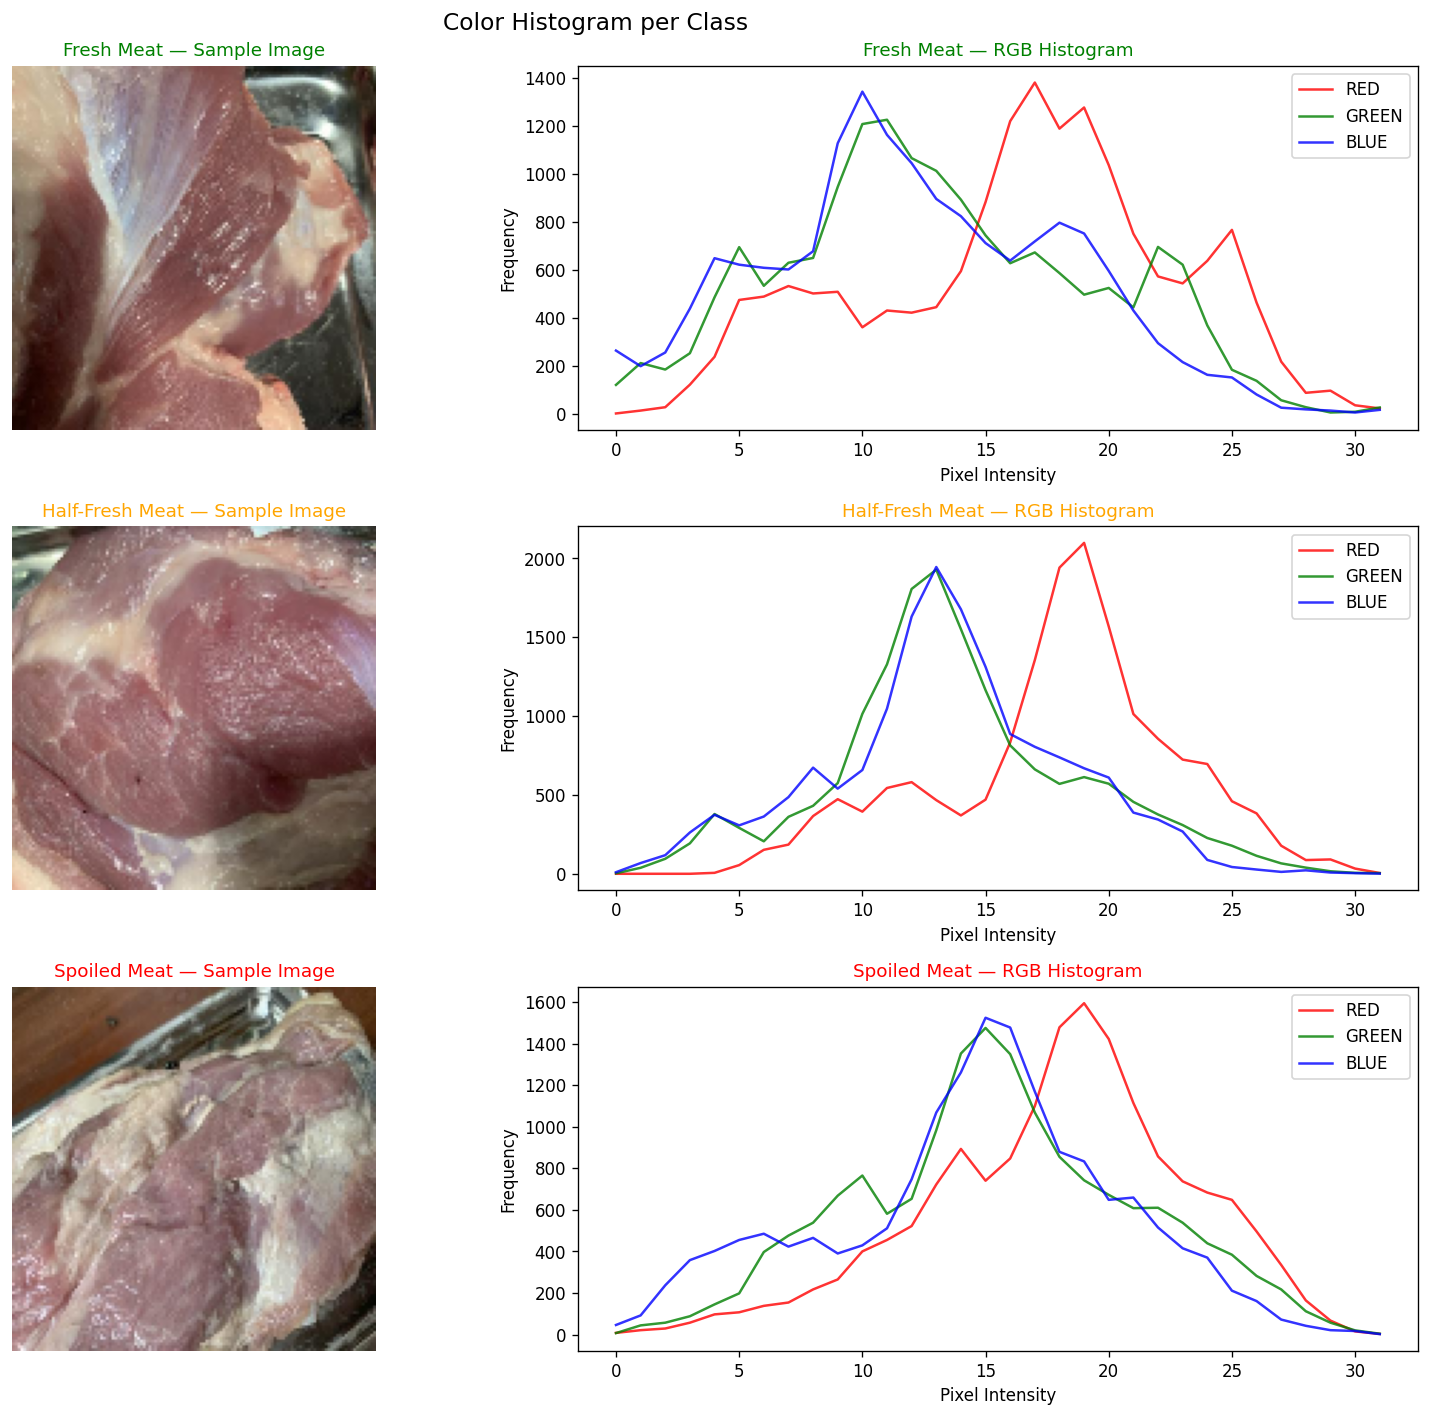

In [ ]:
# ============================================================
# Visualize Color Histogram per Class
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for class_label in [0, 1, 2]:
    sample_path = train_df[train_df["label"] == class_label].sample(1, random_state=SEED)["image_path"].values[0]
    img_bgr = cv2.imread(sample_path)
    img_bgr = cv2.resize(img_bgr, IMG_SIZE)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Show image
    axes[class_label][0].imshow(img_rgb)
    axes[class_label][0].set_title(
        f"{CLASS_NAMES[class_label]} — Sample Image",
        color=CLASS_COLORS[class_label], fontsize=11
    )
    axes[class_label][0].axis("off")

    # Show RGB histograms
    channel_colors = ["red", "green", "blue"]
    for i, col in enumerate(channel_colors):
        hist = cv2.calcHist([img_rgb], [i], None, [HIST_BINS], [0, 256])
        axes[class_label][1].plot(hist, color=col, label=col.upper(), alpha=0.8)

    axes[class_label][1].set_title(
        f"{CLASS_NAMES[class_label]} — RGB Histogram",
        color=CLASS_COLORS[class_label], fontsize=11
    )
    axes[class_label][1].set_xlabel("Pixel Intensity")
    axes[class_label][1].set_ylabel("Frequency")
    axes[class_label][1].legend()

plt.suptitle("Color Histogram per Class", fontsize=14)
plt.tight_layout()
plt.show()

# 8. Building SVM Model

Model SVM dibangun menggunakan **Pipeline** yang menggabungkan:

1. **StandardScaler** — normalisasi fitur agar tiap fitur memiliki mean=0 dan std=1, penting untuk SVM
2. **SVC (Support Vector Classifier)** dengan konfigurasi:
   - `kernel='rbf'` — Radial Basis Function, cocok untuk data non-linear
   - `C=10` — parameter regularisasi
   - `gamma='scale'` — menghitung gamma otomatis dari data
   - `probability=True` — aktifkan output probabilitas (diperlukan untuk ROC Curve)
   - `decision_function_shape='ovr'` — strategi One-vs-Rest untuk multi-class

In [ ]:
# ============================================================
# Build SVM Pipeline
# ============================================================

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm",    SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        probability=True,
        decision_function_shape="ovr",
        random_state=SEED
    ))
])

print("=" * 50)
print("SVM Model Architecture")
print("=" * 50)
print(svm_pipeline)
print()
print("Pipeline Steps :")
print("  1. StandardScaler     — normalisasi fitur")
print("  2. SVC (RBF kernel)   — klasifikasi SVM")
print()
print("SVM Hyperparameters :")
print("  kernel   : rbf")
print("  C        : 10")
print("  gamma    : scale")
print("  strategy : One-vs-Rest (OvR)")

SVM Model Architecture
Pipeline(steps=[('scaler', StandardScaler()),
                ('svm', SVC(C=10, probability=True, random_state=42))])

Pipeline Steps :
  1. StandardScaler     — normalisasi fitur
  2. SVC (RBF kernel)   — klasifikasi SVM

SVM Hyperparameters :
  kernel   : rbf
  C        : 10
  gamma    : scale
  strategy : One-vs-Rest (OvR)


# 9. Model Training

Model SVM dilatih menggunakan seluruh data training yang sudah diekstrak fiturnya.

> ⚠️ SVM dengan dataset besar bisa memakan waktu beberapa menit.

In [ ]:
# ============================================================
# Train SVM Model
# ============================================================

import time

print("Training SVM model...")
start_time = time.time()

svm_pipeline.fit(X_train, y_train)

elapsed = time.time() - start_time

print("=" * 50)
print("Model Successfully Trained!")
print(f"Training Time : {elapsed:.2f} seconds")
print("=" * 50)

Training SVM model...
Model Successfully Trained!
Training Time : 0.70 seconds


# 10. Model Evaluation

Model dievaluasi menggunakan data validasi. Metrik evaluasi yang digunakan:

- **Accuracy** — persentase prediksi yang benar
- **Precision** (weighted) — presisi rata-rata tertimbang per kelas
- **Recall** (weighted) — recall rata-rata tertimbang per kelas
- **F1-Score** (weighted) — harmonic mean dari precision dan recall

In [ ]:
# ============================================================
# Model Evaluation
# ============================================================

# Prediksi kelas
y_pred = svm_pipeline.predict(X_valid)

# Prediksi probabilitas (untuk ROC Curve)
y_pred_prob = svm_pipeline.predict_proba(X_valid)

# Hitung metrik evaluasi
accuracy  = accuracy_score(y_valid, y_pred)
precision = precision_score(y_valid, y_pred, average="weighted")
recall    = recall_score(y_valid, y_pred, average="weighted")
f1        = f1_score(y_valid, y_pred, average="weighted")

# Tampilkan hasil
evaluation = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score" : [accuracy, precision, recall, f1]
})

display(evaluation)

print("=" * 40)
print("Model Evaluation")
print("=" * 40)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

,Metric,Score
0,Accuracy,0.986696
1,Precision,0.986943
2,Recall,0.986696
3,F1-Score,0.986734


Model Evaluation
Accuracy  : 0.9867
Precision : 0.9869
Recall    : 0.9867
F1-Score  : 0.9867


# 11. Confusion Matrix

Confusion matrix menampilkan perbandingan label aktual vs prediksi untuk ketiga kelas:
- **Fresh Meat** (0)
- **Half-Fresh Meat** (1)
- **Spoiled Meat** (2)

Nilai diagonal = prediksi benar. Nilai di luar diagonal = salah klasifikasi.

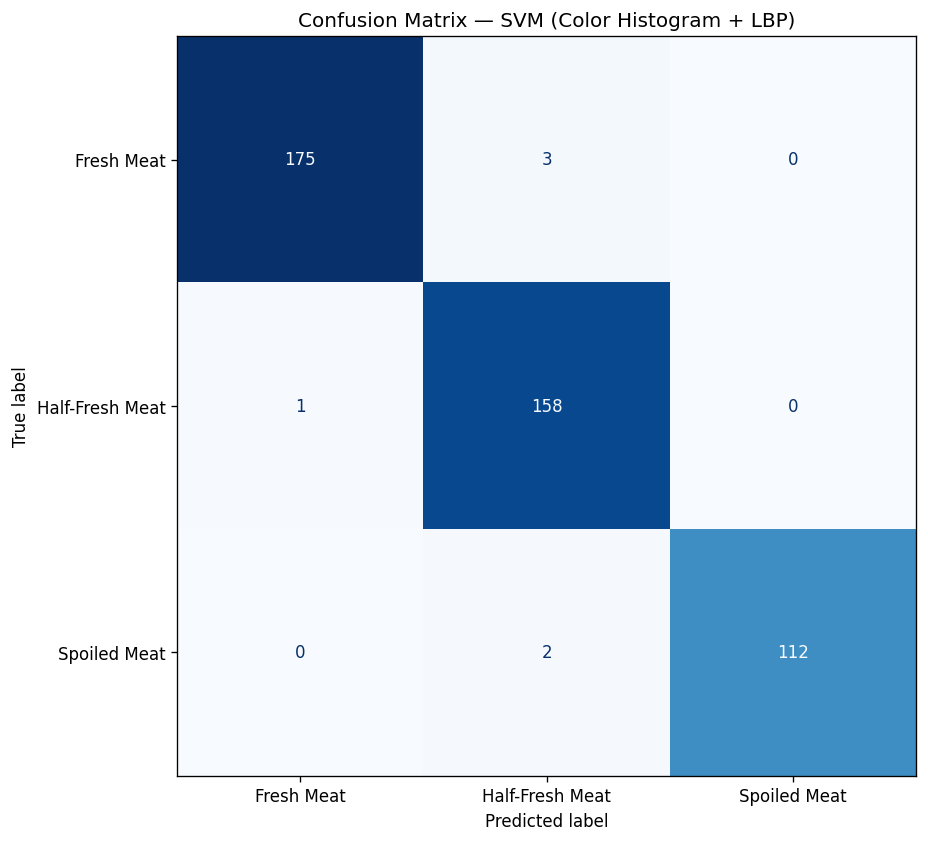

In [ ]:
# ============================================================
# Confusion Matrix
# ============================================================

cm = confusion_matrix(y_valid, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fresh Meat", "Half-Fresh Meat", "Spoiled Meat"]
)

fig, ax = plt.subplots(figsize=(8, 8))

disp.plot(
    cmap="Blues",
    ax=ax,
    colorbar=False
)

plt.title("Confusion Matrix — SVM (Color Histogram + LBP)")
plt.show()

# 12. Classification Report

Laporan klasifikasi menampilkan metrik detail per kelas: Precision, Recall, F1-Score, dan Support.

In [ ]:
# ============================================================
# Classification Report
# ============================================================

print("=" * 60)
print("Classification Report")
print("=" * 60)

print(
    classification_report(
        y_valid,
        y_pred,
        target_names=["Fresh Meat", "Half-Fresh Meat", "Spoiled Meat"],
        digits=4,  # <-- Menampilkan 4 angka di belakang koma
    )
)

Classification Report
                 precision    recall  f1-score   support

     Fresh Meat       0.99      0.98      0.99       178
Half-Fresh Meat       0.97      0.99      0.98       159
   Spoiled Meat       1.00      0.98      0.99       114

       accuracy                           0.99       451
      macro avg       0.99      0.99      0.99       451
   weighted avg       0.99      0.99      0.99       451



# 13. ROC Curve (One-vs-Rest)

ROC Curve untuk klasifikasi multi-kelas menggunakan strategi **One-vs-Rest (OvR)**:
- Tiap kelas diperlakukan sebagai kelas positif, sisanya negatif
- AUC (Area Under the Curve) mendekati **1.0** = model sangat baik

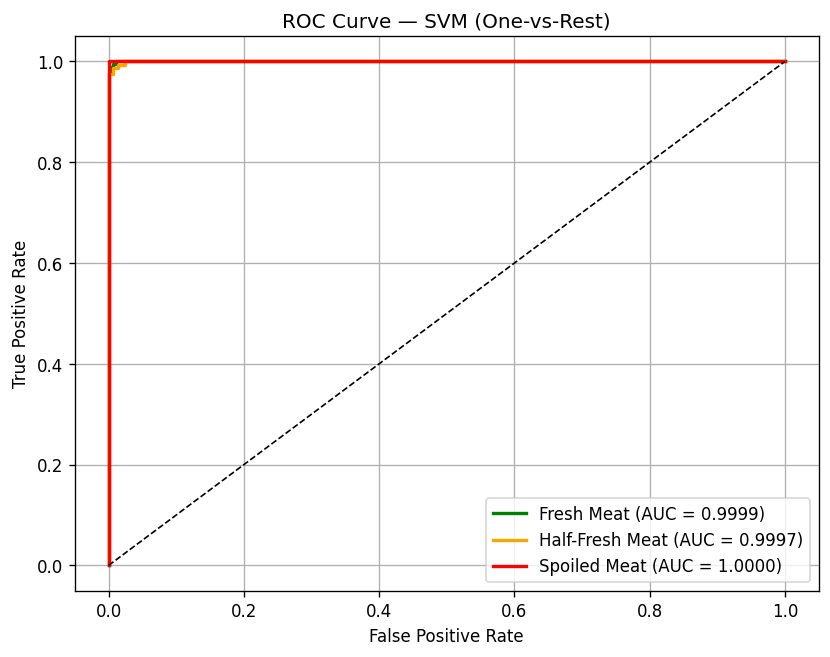

AUC (     Fresh Meat) : 0.9999
AUC (Half-Fresh Meat) : 0.9997
AUC (   Spoiled Meat) : 1.0000


In [ ]:
# ============================================================
# ROC Curve (One-vs-Rest)
# ============================================================

from sklearn.preprocessing import label_binarize

y_valid_bin = label_binarize(y_valid, classes=[0, 1, 2])

class_labels = ["Fresh Meat", "Half-Fresh Meat", "Spoiled Meat"]
line_colors  = ["green", "orange", "red"]

plt.figure(figsize=(8, 6))

auc_scores = []

for i in range(3):
    fpr, tpr, _ = roc_curve(y_valid_bin[:, i], y_pred_prob[:, i])
    roc_auc     = auc(fpr, tpr)
    auc_scores.append(roc_auc)
    plt.plot(fpr, tpr, color=line_colors[i], linewidth=2,
             label=f"{class_labels[i]} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — SVM (One-vs-Rest)")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print("=" * 40)
for i, label in enumerate(class_labels):
    print(f"AUC ({label:>15}) : {auc_scores[i]:.4f}")

# 14. Prediction

Fungsi prediksi untuk gambar baru. Proses:
1. Baca dan resize gambar
2. Ekstrak Color Histogram + LBP
3. Masukkan ke SVM pipeline (scaler + SVM)
4. Output: kelas prediksi + confidence score

Sample: SPOILED-726-_JPG.rf.84dacc087202efc5f2c8cd50b7d47974.jpg


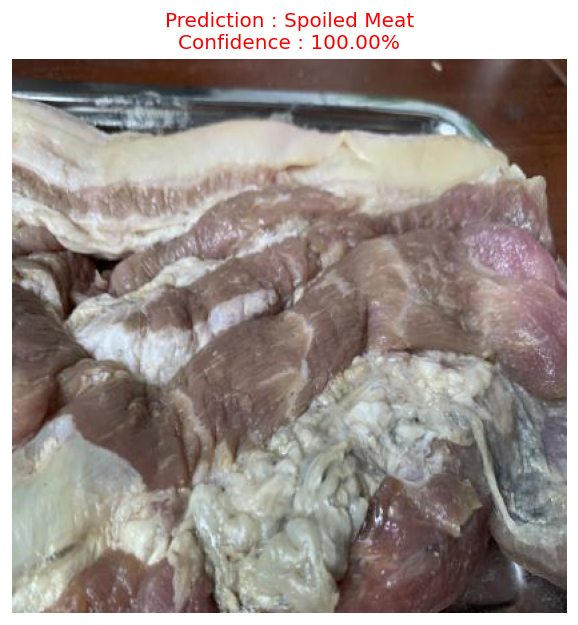

Prediction : Spoiled Meat
Confidence : 100.00%
Probabilities:
         Fresh Meat : 0.0000
    Half-Fresh Meat : 0.0000
       Spoiled Meat : 1.0000


In [ ]:
# ============================================================
# Prediction Function
# ============================================================

def predict_image(image_path):
    """
    Prediksi kesegaran daging dari path gambar.
    """
    # Baca gambar
    image = cv2.imread(image_path)

    if image is None:
        print("Image cannot be loaded!")
        return

    # Ekstrak fitur
    features = extract_features(image_path)

    if features is None:
        print("Feature extraction failed!")
        return

    # Prediksi
    pred_class   = svm_pipeline.predict([features])[0]
    pred_proba   = svm_pipeline.predict_proba([features])[0]
    confidence   = pred_proba[pred_class]
    prediction   = CLASS_NAMES[pred_class]

    # Tampilkan hasil
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(6, 6))
    plt.imshow(image_rgb)
    plt.title(
        f"Prediction : {prediction}\nConfidence : {confidence:.2%}",
        color=CLASS_COLORS[pred_class],
        fontsize=12
    )
    plt.axis("off")
    plt.show()

    print("=" * 40)
    print("Prediction :", prediction)
    print(f"Confidence : {confidence:.2%}")
    print("Probabilities:")
    for i, label in CLASS_NAMES.items():
        print(f"  {label:>17} : {pred_proba[i]:.4f}")
    print("=" * 40)


# ============================================================
# Contoh Penggunaan
# ============================================================
# predict_image("/path/to/image.jpg")
# Ganti path di atas dengan path gambar yang ingin diprediksi

# Contoh: prediksi gambar dari validation set
sample_path = valid_df.sample(1, random_state=SEED)["image_path"].values[0]
print(f"Sample: {os.path.basename(sample_path)}")
predict_image(sample_path)

# 15. Save Model

Model SVM pipeline (StandardScaler + SVM) disimpan menggunakan **joblib** dalam format `.pkl`.

Format `.pkl` digunakan karena SVM adalah model scikit-learn dan tidak mendukung format TFLite. File ini dapat dimuat kembali menggunakan `joblib.load()` untuk prediksi tanpa melatih ulang.

In [ ]:
# ============================================================
# Save Model
# ============================================================

model_filename = "svm_meat_freshness.pkl"

joblib.dump(svm_pipeline, model_filename)

print("=" * 50)
print("Model Successfully Saved!")
print(f"File Name  : {model_filename}")
print("Format     : scikit-learn Pipeline (.pkl)")
print("Classifier : SVM (RBF Kernel)")
print("Features   : Color Histogram (RGB+HSV) + LBP")
print("Classes    : Fresh Meat / Half-Fresh Meat / Spoiled Meat")
print("=" * 50)

# ============================================================
# Cara load model
# ============================================================
# loaded_model = joblib.load("svm_meat_freshness.pkl")
# y_pred = loaded_model.predict(X_valid)

Model Successfully Saved!
File Name  : svm_meat_freshness.pkl
Format     : scikit-learn Pipeline (.pkl)
Classifier : SVM (RBF Kernel)
Features   : Color Histogram (RGB+HSV) + LBP
Classes    : Fresh Meat / Half-Fresh Meat / Spoiled Meat


# 16. Discussion

Model SVM dengan kombinasi fitur **Color Histogram + LBP** berhasil mengklasifikasikan daging ke dalam tiga kategori: **Fresh Meat**, **Half-Fresh Meat**, dan **Spoiled Meat**.

### Kenapa SVM?
SVM adalah model Traditional Machine Learning yang bekerja dengan mencari **hyperplane optimal** yang memisahkan kelas-kelas dalam ruang fitur berdimensi tinggi. Dengan kernel RBF, SVM mampu menangani data yang tidak dapat dipisahkan secara linear.

### Kenapa Color Histogram?
Perubahan kesegaran daging paling terlihat dari **warna**:
- **Fresh Meat**: merah cerah, tinggi nilai channel R
- **Half-Fresh Meat**: merah pucat, mulai kecoklatan
- **Spoiled Meat**: coklat tua, abu-abu, atau kehijauan

### Kenapa LBP?
Selain warna, **tekstur permukaan** daging juga berubah seiring membusuknya:
- Daging segar: tekstur halus dan berkilap
- Daging busuk: tekstur kasar, berlendir, atau kering

LBP menangkap pola tekstur lokal yang tidak tertangkap oleh color histogram.

### Kelebihan
- Tidak memerlukan GPU atau resource komputasi besar
- Fitur yang digunakan memiliki **interpretabilitas tinggi**
- Training jauh lebih cepat dibanding Deep Learning
- Tidak memerlukan banyak data training

### Keterbatasan
- Bergantung pada kualitas feature engineering yang dilakukan manual
- Kurang robust terhadap variasi pencahayaan ekstrem
- Akurasi umumnya lebih rendah dibanding Deep Learning pada dataset besar
- SVM tidak mendukung format TFLite (deployment mobile membutuhkan konversi tambahan)

# 17. Conclusion

Proyek ini berhasil membangun model **Traditional Machine Learning (SVM)** untuk klasifikasi kesegaran daging ke dalam tiga kategori: **Fresh Meat**, **Half-Fresh Meat**, dan **Spoiled Meat**.

Pipeline yang dibangun:
1. **Feature Extraction** — Color Histogram (RGB + HSV) + Local Binary Pattern (LBP)
2. **Normalization** — StandardScaler
3. **Classification** — Support Vector Machine (SVM, kernel RBF)

Model dievaluasi menggunakan metrik **Accuracy**, **Precision**, **Recall**, **F1-Score**, **Confusion Matrix**, dan **ROC Curve (OvR)**, serta disimpan dalam format **`.pkl`** menggunakan joblib untuk penggunaan ulang.

Pengembangan selanjutnya dapat meliputi:
- Hyperparameter tuning (Grid Search / Random Search)
- Eksplorasi fitur tambahan seperti GLCM atau HOG
- Penerapan data augmentation untuk memperkaya dataset
- Perbandingan dengan model lain (Random Forest, XGBoost, K-NN)